<div align = 'center'>
<h1>Health in Nature and People in London Boroughs</h1>
</div>
<ul>
<li><em>Student ID:</em> 24000117484</li>
<li><em>Repository:</em> M6006-ds2026-24000117484</li>
</ul>



<div align = 'center'>
<h1> Research Question</h1>  <h2>What Effect does Green Space have on the Health of London Borough Residents, How strong is that effect and are there any other factors involved</h2>


In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import sympy as sp

## Cleaning

In [2]:
#health = pd.read_csv('Data/la_health.csv')
demo = pd.read_excel('Data/File_10_-_IoD2025_Local_Authority_District_Summaries__lower-tier__v2.xlsx', sheet_name=['Health', 'Income'])

health = demo['Health']
health = health[health['Local Authority District code (2024)'].str.contains('E09', na=False)]

wealth = demo['Income']
wealth = wealth[wealth['Local Authority District code (2024)'].str.contains('E09', na=False)]

#g_cover = pd.read_csv('Data/g_cover.csv')
g_cover = pd.read_excel('Data/green_cover_borough_summary_0.05.xlsx', sheet_name='borough_green_cover')


In [3]:
health

,Local Authority District code (2024),Local Authority District name (2024),Health Deprivation and Disability - Average rank,Health Deprivation and Disability - Rank of average rank,Health Deprivation and Disability - Average score,Health Deprivation and Disability - Rank of average score,Health Deprivation and Disability - Proportion of LSOAs in most deprived 10% nationally,Health Deprivation and Disability - Rank of proportion of LSOAs in most deprived 10% nationally
263,E09000001,City of London,11922.62,201,-0.529,219,0.0000,178
264,E09000002,Barking and Dagenham,20770.80,77,0.265,84,0.0087,170
265,E09000003,Barnet,7920.41,261,-0.790,262,0.0000,178
266,E09000004,Bexley,13000.64,184,-0.327,186,0.0068,174
267,E09000005,Brent,13509.92,175,-0.281,175,0.0055,175
268,E09000006,Bromley,8582.31,250,-0.773,257,0.0000,178
269,E09000007,Camden,18017.99,110,0.047,120,0.0308,129
270,E09000008,Croydon,15260.10,153,-0.149,153,0.0087,169
271,E09000009,Ealing,13434.20,177,-0.298,180,0.0000,178
272,E09000010,Enfield,13841.69,170,-0.279,174,0.0000,178


In [4]:
g_cover.head()

,lb_code,lb_name,borough_area_hectare,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue
0,Havering,E09000016,11445.736,7551.971148,401.810236,7953.781384,65.980651,3.510567,69.491218
1,Bromley,E09000006,15013.487,10262.639922,56.961015,10319.600937,68.356138,0.379399,68.735537
2,Richmond upon Thames,E09000027,5876.109,3642.676453,307.938502,3950.614955,61.991302,5.240517,67.231819
3,Barnet,E09000003,8674.835,5030.909762,60.010101,5090.919864,57.994299,0.691772,58.686071
4,Enfield,E09000010,8220.024,4352.729074,424.013507,4776.742581,52.952754,5.158300,58.111054


In [5]:
# Printing column names

print('wealth: ', wealth.columns, '\nhealth:', health.columns, '\ngreen cover:', g_cover.columns)

wealth:  Index(['Local Authority District code (2024)',
       'Local Authority District name (2024)', 'Income - Average rank ',
       'Income - Rank of average rank ', 'Income - Average score ',
       'Income - Rank of average score ',
       'Income - Proportion of LSOAs in most deprived 10% nationally ',
       'Income - Rank of proportion of LSOAs in most deprived 10% nationally ',
       'Income scale', 'Rank of Income Scale'],
      dtype='str') 
health: Index(['Local Authority District code (2024)',
       'Local Authority District name (2024)',
       'Health Deprivation and Disability - Average rank ',
       'Health Deprivation and Disability - Rank of average rank ',
       'Health Deprivation and Disability - Average score ',
       'Health Deprivation and Disability - Rank of average score ',
       'Health Deprivation and Disability - Proportion of LSOAs in most deprived 10% nationally ',
       'Health Deprivation and Disability - Rank of proportion of LSOAs in most de

In [6]:
# Fixing incorrect column names
g_cover = g_cover.rename(columns={
    'lb_code': 'borough',
    'lb_name': 'lb_code'
})

# Simplifying and matching column names for borough names
health = health.rename(columns={
    'Local Authority District name (2024)': 'borough',
})

wealth = wealth.rename(columns={
    'Local Authority District name (2024)': 'borough',
    
})



In [7]:
# Eliminating white space and capitals in column titles and borough names for ease
def clean_text(s):
    return s.astype("string").str.strip().str.lower()

wealth.columns = clean_text(wealth.columns)
wealth['borough'] = clean_text(wealth['borough'])

health.columns = clean_text(health.columns)
health['borough'] = clean_text(health['borough'])

g_cover.columns = clean_text(g_cover.columns)
g_cover['borough'] = clean_text(g_cover['borough'])

In [8]:
health.columns

Index(['local authority district code (2024)', 'borough',
       'health deprivation and disability - average rank',
       'health deprivation and disability - rank of average rank',
       'health deprivation and disability - average score',
       'health deprivation and disability - rank of average score',
       'health deprivation and disability - proportion of lsoas in most deprived 10% nationally',
       'health deprivation and disability - rank of proportion of lsoas in most deprived 10% nationally'],
      dtype='string')

In [9]:
# Identifying any boroughs not present in all datasets

a = set(health['borough'])
b = set(wealth['borough'])
c = set(g_cover['borough'])

for value in sorted(a ^ b):
    if value in a:
        print(f"{value} is in health but not wealth")
    else:
        print(f"{value} is in wealth but not health")

# As all boroughs are shared in health and wealth check health against g_cover

for value in sorted(a ^ c):
    if value in a:
        print(f"{value} is in health but not g_cover")
    else:
        print(f"{value} is in g_cover but not health")

city of westminster is in g_cover but not health
westminster is in health but not g_cover


In [10]:
# Finding the missing borough in health

west = health['borough'].str.contains('westminster')

print(health.loc[west, 'borough'])

295    westminster
Name: borough, dtype: string


In [11]:
# Renaming the missing borough

west = g_cover['borough'].str.contains('westminster')
g_cover.loc[west, 'borough'] = 'westminster'

In [12]:
# Checking both datasets are the same length

print(len(health['borough']) - len(wealth['borough']))
print(len(g_cover['borough']) - len(health['borough']))

0
0


In [13]:
# Creatng a list of the London Boroughs

boroughs = g_cover['borough'] 


In [14]:
N = len(health['borough']) # Length of health and wealth borough columns, both are the same length so only one needed
G = len(g_cover) # Length of g_cover borough dataset (actual number of boroughs in London)


# Creating a list of all rows that match the values in 'boroughs' and setting the datasets to only contain those rows

lbs_h = health['borough'].isin(boroughs)
health = health[lbs_h]

lbs_w = wealth['borough'].isin(boroughs)
wealth = wealth[lbs_w]





In [15]:
# Selecting only relevant columns for wealth and health
# Average score used as it is the best indicator for each dataset for the variable I want to identify

wealth = wealth.loc[:, [
    'borough', 'income - average score'
]]

health = health.loc[:, [
    'borough', 'health deprivation and disability - average score'
]]

# Merging wealth and health datasets

lb_demo = pd.merge(wealth, health, how='inner', on='borough')

# Merging demographics (wealth and health) dataset with green and blue cover dataset

data = pd.merge(g_cover, lb_demo, how='inner', on='borough')

In [16]:
data.head()

,borough,lb_code,borough_area_hectare,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,income - average score,health deprivation and disability - average score
0,havering,E09000016,11445.736,7551.971148,401.810236,7953.781384,65.980651,3.510567,69.491218,0.203,-0.401
1,bromley,E09000006,15013.487,10262.639922,56.961015,10319.600937,68.356138,0.379399,68.735537,0.158,-0.773
2,richmond upon thames,E09000027,5876.109,3642.676453,307.938502,3950.614955,61.991302,5.240517,67.231819,0.122,-1.382
3,barnet,E09000003,8674.835,5030.909762,60.010101,5090.919864,57.994299,0.691772,58.686071,0.257,-0.790
4,enfield,E09000010,8220.024,4352.729074,424.013507,4776.742581,52.952754,5.158300,58.111054,0.377,-0.279


In [17]:
# Making sure the new dataset is still the same length as the old datasets -1 to old datasets for borough column

print(len(data.columns) - (len(g_cover.columns) - 1 + len(lb_demo.columns)))

# Checking row length are the same
print(data.shape[0] - g_cover.shape[0])
print(data.shape[0] - lb_demo.shape[0])

0
0
0


In [18]:
# Checking any missing boroughs between g_cover (which is no the same as health and wealth) and data

a = set(data["borough"])
b = set(g_cover["borough"])

for value in sorted(a ^ b):
    if value in a:
        print(f"{value} is in data but not g_cover")
    else:
        print(f"{value} is in g_cover but not data")

In [19]:
# Inverting health and wealth scores for easier understanding

data = data.assign(
    health_score=data['health deprivation and disability - average score']*-1,
    wealth_score=data['income - average score']*-1
).drop(columns=['income - average score', 'health deprivation and disability - average score'])

In [20]:
#Checking for any null values

print(' --------\nNull Values\n --------', '\n', data.isna().sum())


 --------
Null Values
 -------- 
 borough                    0
lb_code                    0
borough_area_hectare       0
green_area_hectare         0
blue _area_hectare         0
green+blue_area_hectare    0
percent_green              0
percent_blue               0
percent_green+blue         0
health_score               0
wealth_score               0
dtype: int64


In [21]:
# Writing cleaned dataset to a file
data.to_csv('Data/borough_demographics.csv', index=False)

## Initial Analysis

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

data.columns

Index(['borough', 'lb_code', 'borough_area_hectare', 'green_area_hectare',
       'blue _area_hectare', 'green+blue_area_hectare', 'percent_green',
       'percent_blue', 'percent_green+blue', 'health_score', 'wealth_score'],
      dtype='string')

In [23]:


data1 = data.loc[:,[
    'green_area_hectare', 'blue _area_hectare', 'green+blue_area_hectare',
    'percent_green', 'percent_blue', 'percent_green+blue',
    'wealth_score', 'health_score', 'borough_area_hectare'
]]

In [24]:
data1.describe()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score,borough_area_hectare
count,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000
mean,2434.173244,140.778912,2574.952156,43.614715,3.296664,46.911378,-0.264606,0.274697,4832.415848
std,2248.099471,142.440866,2295.462523,12.807678,2.938065,11.721499,0.082189,0.432708,3277.031819
min,17.608124,3.952986,41.922343,5.590892,0.133674,13.311089,-0.401000,-0.602000,314.943000
25%,943.019741,31.924078,962.833065,37.665919,0.909313,40.967720,-0.304000,-0.047000,2724.941000
50%,1726.558641,60.010101,1867.288417,43.278949,2.306622,45.299271,-0.266000,0.298000,3857.807000
75%,2796.612342,242.103989,3103.005841,52.952754,5.158300,54.976660,-0.203000,0.559000,5658.541000
max,10262.639922,437.519987,10319.600937,68.356138,11.752282,69.491218,-0.066000,1.382000,15013.487000


### Correlation

.corr() looks for correlation between variables. We invert the health scores and wealth scores and assign them health and wealth for ease of interpretation. High scores reflect low health or wealth so this change allows easier identification of a positive or negative correlation between green/blue space and health and wealth.



In [25]:
data1.corr()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score,borough_area_hectare
green_area_hectare,1.000000,0.304333,0.998251,0.809332,-0.241810,0.823718,0.225279,0.408044,0.984774
blue _area_hectare,0.304333,1.000000,0.360106,0.189845,0.666467,0.374492,-0.130543,-0.039407,0.384572
green+blue_area_hectare,0.998251,0.360106,1.000000,0.804413,-0.195464,0.829960,0.212530,0.397179,0.988319
percent_green,0.809332,0.189845,0.804413,1.000000,-0.468715,0.975179,0.116389,0.467651,0.802296
percent_blue,-0.241810,0.666467,-0.195464,-0.468715,1.000000,-0.261492,-0.147131,-0.253847,-0.198467
percent_green+blue,0.823718,0.374492,0.829960,0.975179,-0.261492,1.000000,0.090294,0.447357,0.826894
wealth_score,0.225279,-0.130543,0.212530,0.116389,-0.147131,0.090294,1.000000,0.703362,0.141272
health_score,0.408044,-0.039407,0.397179,0.467651,-0.253847,0.447357,0.703362,1.000000,0.359209
borough_area_hectare,0.984774,0.384572,0.988319,0.802296,-0.198467,0.826894,0.141272,0.359209,1.000000


### Correlation output intrepretation

We can see a positive correlation between the health and wealth values and the percentage of the borough made up of a combination of green and blue space. Looking at the % variables for only green and blue space we can see a negative correlation between both percent of the borough comprised of blue space and the total area of blue space with both health and wealth, however these values are small so are unlikely to indicate a statisticall informative relation between the variables. For green space we can see a high correlation between green space area and percentage with health (relative to the other relationships shown in the table), however there is a lower correlation between green space (% and area) and wealth.

The highest correlation is between wealth and health, reflecting poor health is often a result of economic inequality. The correlation between green space and health is likely due to areas with higher economic inequality having less funding and interest in maintaining and creating new green spaces (likely as a result of funding priorites being linked to combating underlying drivers of economic inequality, like a lack of jobs or underfunded education systems).


<body style="background-color:powderblue;">

<h3>To do</h3>

<form>
  <div>
    <input
      type="checkbox"
      id="action_1"
    />
    <label for="action_1">health-wealth correlation further depth and add figure</label>
    </div>
    <div>
    <input
    type='checkbox'
    id='action_2'
    />
    <label for='action_2'>Explicitly state moderate correlation of 0.4 between green and health/wealth</label>
  </div>
  <div>
  <input
  type='checkbox'
  id='action_3'
  />
  <label for='action_3'>blue correlations very weak</label>
  </div>
  <div>
  <input
  type='checkbox'
  id='action_4'
  />
  <label for='action_4'>cite assumptions of underlying causes for associations where stated</label>
  <div>
  <input
  type='checkbox'
  id='action_5'
  />
  <label for='action_5'>talk about city of london</label>





</form>

</body>

In [26]:
x = data['wealth_score']
y = data['health_score']
z = data['percent_green+blue']



In [27]:
df = data
fig = px.scatter_3d(df, x='wealth_score', y='percent_green', z='health_score',
              hover_data='borough', title='Scatter Plot of Health against Green Spaces and Wealth', opacity=0.4)
fig.show()

In the 3D scatter plot displayed above, we can see a generally linear relationship between the amount of green cover and wealth in a borough and the health of the residents. We can also see an outlier, hovering over it identifies it as the City of London so we will now compare plots 

### Removing the City of London

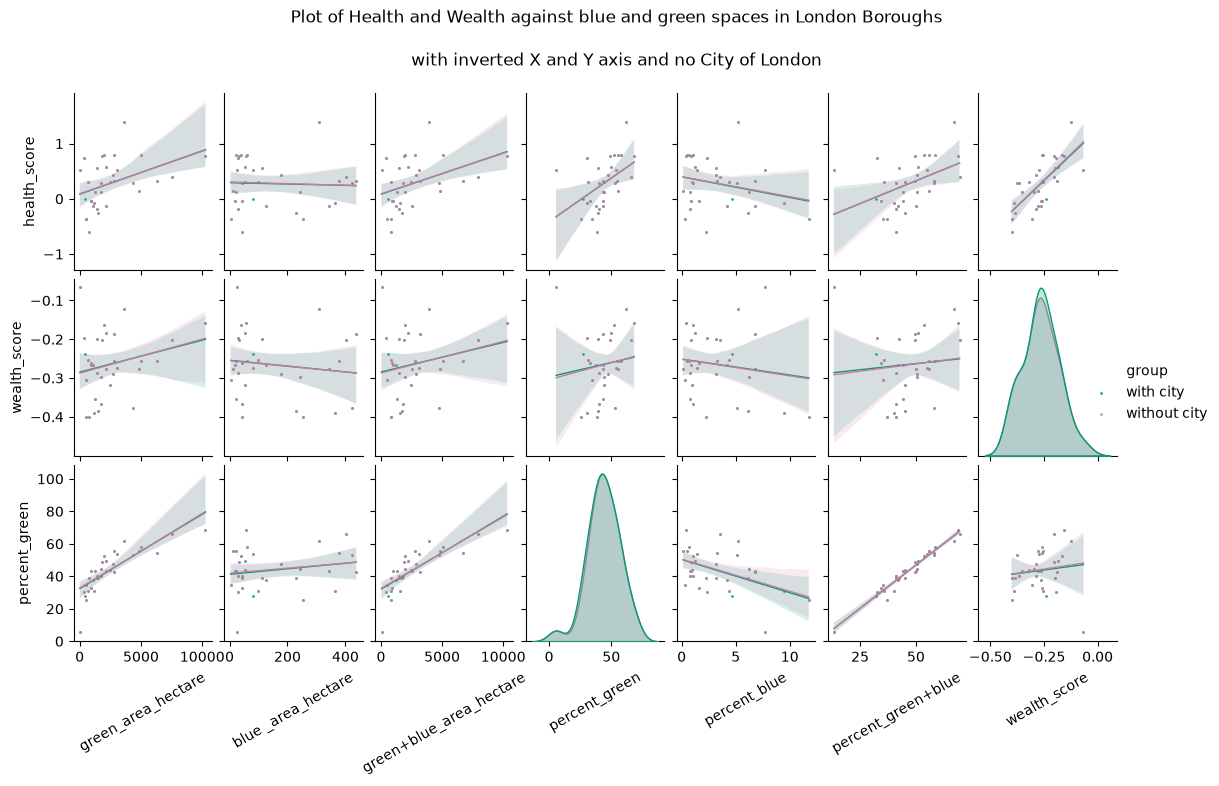

In [39]:
data_cl = data1.drop(index=31)

data1['group'] = 'with city'
data_cl['group'] = 'without city'

compared = pd.concat([data1, data_cl], ignore_index=True)

plot = sns.pairplot(data=compared,
             kind='reg', 
             y_vars = ['health_score', 'wealth_score', 'percent_green'],
             x_vars = ['green_area_hectare', 'blue _area_hectare', 'green+blue_area_hectare',
                     'percent_green', 'percent_blue', 'percent_green+blue', 'wealth_score'],
             hue = 'group',
             palette = {
                 'with city': '#009E73',
                 'without city': '#CC79A7'
             },
             plot_kws={'scatter_kws': {'s': 1},
                       'line_kws': {'lw': 1}                        
                 
             })

for ax in plot.axes[-1, :]:
    ax.xaxis.label.set_rotation(30)
plot.figure.set_size_inches(12,7)
plot.fig.text(0.5,0.9, 'with inverted X and Y axis and no City of London', ha='center', fontsize=12)
plot.fig.subplots_adjust(top=0.86)
plt.suptitle('Plot of Health and Wealth against blue and green spaces in London Boroughs')


plt.show()

Wealth score shows a strong positive association with health score, whereas it is only weakly related to green and blue space. Wealth will therefore be included as a covariate so that any association between green space and health is estimated independently of it. Because green space and wealth are largely uncorrelated, multicollinearity is unlikely to be an issue. The variables for green and blue space all show similar patterns (as they all measure similiar things) so only percent_green will be included to avoid multicollinearity and overfitting. We can also see a small bump in the percent_green density curve, indiciating an outlier borough in the amount of green space. An outlier is also visible in the wealth score. Sorting the dataset by percent_green and wealth shows this outlier to be the City of London each time, which confirms the earlier identification of the borough being atypical.

In [29]:

data_cl.drop(columns='group').corr()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score,borough_area_hectare
green_area_hectare,1.000000,0.296759,0.998208,0.804382,-0.232701,0.819342,0.237330,0.397664,0.984460
blue _area_hectare,0.296759,1.000000,0.353365,0.177527,0.677030,0.367584,-0.126794,-0.048685,0.378031
green+blue_area_hectare,0.998208,0.353365,1.000000,0.799108,-0.185537,0.825671,0.224548,0.386507,0.988078
percent_green,0.804382,0.177527,0.799108,1.000000,-0.463784,0.973859,0.132533,0.456620,0.795659
percent_blue,-0.232701,0.677030,-0.185537,-0.463784,1.000000,-0.250414,-0.152426,-0.246996,-0.187946
percent_green+blue,0.819342,0.367584,0.825671,0.973859,-0.250414,1.000000,0.105747,0.435653,0.821285
wealth_score,0.237330,-0.126794,0.224548,0.132533,-0.152426,0.105747,1.000000,0.715510,0.153310
health_score,0.397664,-0.048685,0.386507,0.456620,-0.246996,0.435653,0.715510,1.000000,0.347075
borough_area_hectare,0.984460,0.378031,0.988078,0.795659,-0.187946,0.821285,0.153310,0.347075,1.000000


We can see a positive correlation between the percentage of a borough's area that is comprised of green space and wealth with health for residents (0.643335 and 0.733931 respectively) while the percentage of blue space shows a negative correlation with both health and wealth.

In [30]:
# Regression Analysis

import statsmodels.api as sm
formula_string = "Q('health_score') ~ Q('percent_green') + Q('wealth_score')"

model_full = sm.formula.ols(formula = formula_string, data = data_cl)
model_full_fitted = model_full.fit()

fstring_g = "Q('health_score') ~ Q('percent_green')"
fstring_w = "Q('health_score') ~ Q('wealth_score')"

model_g = sm.formula.ols(formula = fstring_g, data = data_cl)
model_g_fitted = model_g.fit()

model_w = sm.formula.ols(formula = fstring_w, data = data_cl)
model_w_fitted = model_w.fit()


r = sp.symbols('r')
r2 = r**2
ar = 'Adj.' + r'$r^2$'
print(model_full_fitted.summary(),'\n','' \
'Green space (% of borough): ', 'p-value = ', model_full_fitted.pvalues["Q('percent_green')"],'   ' 'R² = ', 
model_g_fitted.rsquared, '   ', 'Adj. R² = ', model_g_fitted.rsquared_adj, '\n',
'Wealth Score: ', model_full_fitted.pvalues["Q('wealth_score')"],'   ', 'R² = ', 
model_w_fitted.rsquared, '   ', 'Adj. R² = ', model_w_fitted.rsquared_adj)

                            OLS Regression Results                            
Dep. Variable:      Q('health_score')   R-squared:                       0.645
Model:                            OLS   Adj. R-squared:                  0.621
Method:                 Least Squares   F-statistic:                     26.37
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           2.99e-07
Time:                        19:07:15   Log-Likelihood:                -1.8120
No. Observations:                  32   AIC:                             9.624
Df Residuals:                      29   BIC:                             14.02
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.6507      0

The regression analysis shows the wealth (through the wealth_score variable) and amount of green space relative to the borough size (through the percent_green variable) have a  statistically significant association with health scores (the dependent variable - health_score) for borough residents. The analysis shows that wealth and green space can explain $65\%$ of the variance in the health variable with $p\leq 0.05$ for each independent variable (when the other is held constant).

Both the $R^2$ and Adj. $R^2$ are higher when both green space and wealth variables are used, compared to each variable individually. This shows that the combination of the variables have a higher correlation than each one individually. However, wealth has a higher independent $R^2$ and Adj. $R^2$ compared to the amount of green space.


The analysis covers 32 Boroughs (excluding the City of London) and does not establish causation and only shows how the independent variables vary with the dependent variable.

### Compare against a regression model including the City of London

In [31]:
model_fullc = sm.formula.ols(formula = formula_string, data=data)
model_fullc_fitted = model_fullc.fit()

model_gc = sm.formula.ols(formula = fstring_g, data = data)
model_gc_fitted = model_gc.fit()

model_wc = sm.formula.ols(formula = fstring_w, data = data)
model_wc_fitted = model_wc.fit()

print(model_fullc_fitted.summary(), '\n','' \
'Green space (% of borough): ', 'p-value = ', model_fullc_fitted.pvalues["Q('percent_green')"],'   ' 'R² = ', 
model_gc_fitted.rsquared, '   ', 'Adj. R² = ', model_gc_fitted.rsquared_adj, '\n',
'Wealth Score: ', model_fullc_fitted.pvalues["Q('wealth_score')"],'   ', 'R² = ', 
model_wc_fitted.rsquared, '   ', 'Adj. R² = ', model_wc_fitted.rsquared_adj)

                            OLS Regression Results                            
Dep. Variable:      Q('health_score')   R-squared:                       0.646
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     27.32
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           1.75e-07
Time:                        19:07:15   Log-Likelihood:                -1.5577
No. Observations:                  33   AIC:                             9.115
Df Residuals:                      30   BIC:                             13.61
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.6149      0

In the regression model including the City of London we can see that the $R^2$ and Adj. $R^2$ turns out higher in comparison to the model without the City of London